# 01 — Exploratory Data Analysis of METR-LA

This notebook checks data quality and the statistical structure of the METR-LA
traffic-speed dataset. Every plotting and statistics function lives in
`src/traffic/eda.py`, so `scripts/run_eda.py` reproduces the same figures for
the report.

**Questions answered**
1. How large and how clean is the data? How are missing values encoded?
2. What temporal patterns exist (daily and weekly seasonality, persistence)?
3. Is the series stationary?
4. Is there spatial dependence, and does the road graph capture it?
5. Is the chronological train/val/test split representative?

In [1]:
import numpy as np, pandas as pd
from IPython.display import display
from traffic import eda, plotting as P
from traffic.data import load_metrla, distance_matrix
P.setup()
d = load_metrla()
pd.Series(eda.summary(d)).to_frame("value")

,value
time_steps,34272
sensors,207
start,2012-03-01 00:00:00
end,2012-06-27 23:55:00
days,119
interval_min,5
missing_pct,8.109351
all_sensor_outage_steps,2148
speed_mean,58.459724
speed_std,13.023602


## 1. Data quality

* 34,272 five-minute steps × 207 sensors (1 Mar – 27 Jun 2012, 119 days), with no gaps in the time index.
* **Missing values are encoded as `0`**, not NaN. A speed of exactly 0 mph on a
  freeway is a sensor dropout, never a real reading (true minimum observed speed > 0).
  About 8.1 % of readings are missing. These zeros are **masked** in every loss and
  metric and are never treated as real speeds.
* Speeds are capped at 70 mph by the sensors' processing, so the distribution is truncated at the top.

{'per_sensor_missing_pct': {'min': 6.26750700280112,
  'median': 6.973622782446312,
  'max': 20.10387488328665},
 'days_over_50pct_missing': ['2012-03-26',
  '2012-03-27',
  '2012-04-08',
  '2012-04-25',
  '2012-06-17'],
 'longest_gap_steps_median': 381}

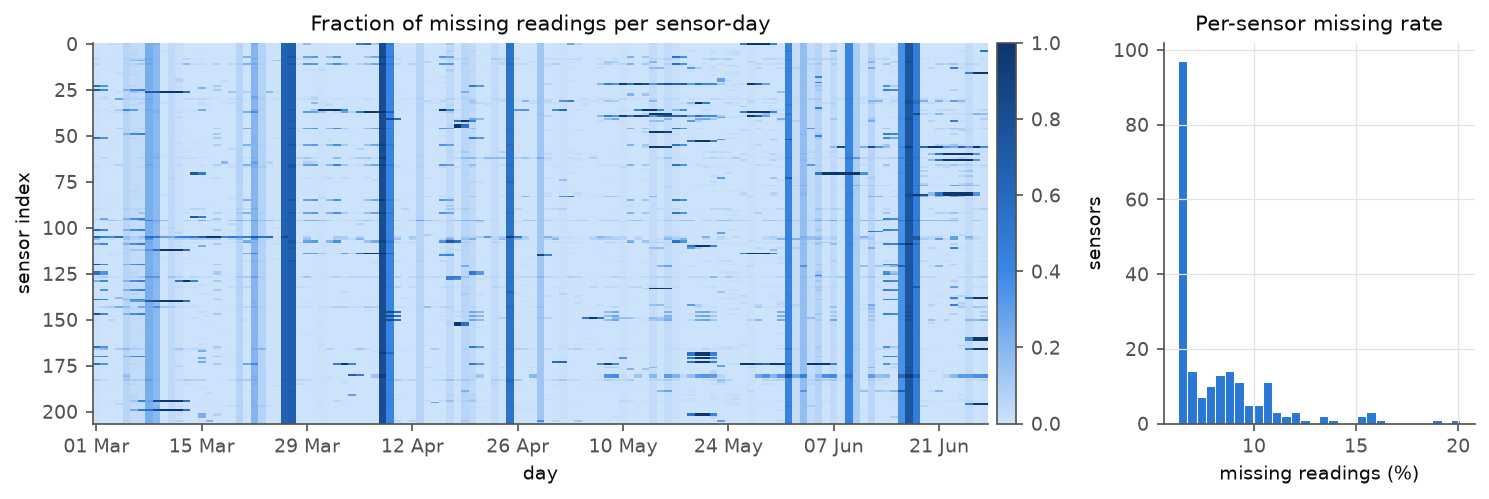

In [2]:
fig, s = eda.missingness(d); display(s)

The vertical stripes are network-wide **outages** (whole days in which most sensors
report 0, e.g. 26–27 Mar). The horizontal streaks are individual sensors failing for
long stretches; the median sensor's longest outage is 381 steps (≈ 32 hours). Consequences:

* forward-filling is used **only for features** (it is causal) and never to create labels;
* a model must stay robust when its most recent input is missing. This is measured in the results.

{}

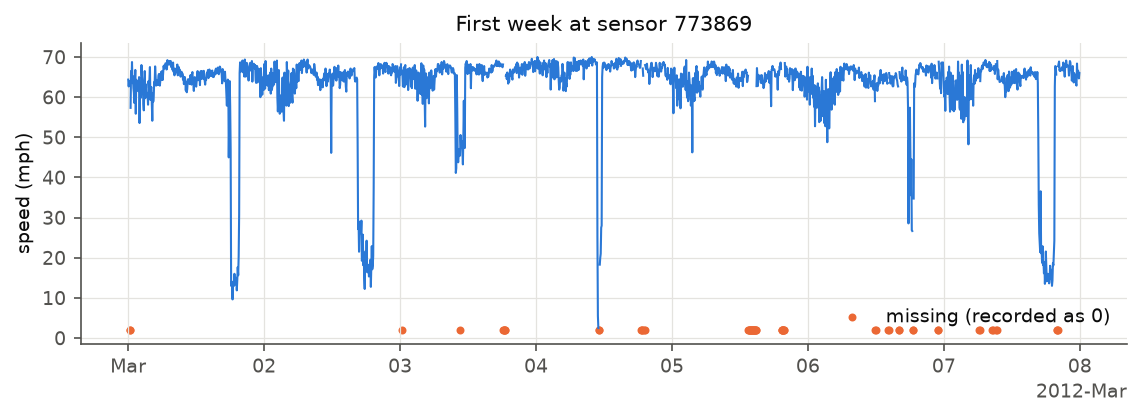

In [3]:
fig, s = eda.example_week(d); s

{'percentiles_1_5_25_50_75_95_99': [13.12,
  25.62,
  57.12,
  63.22,
  66.5,
  68.89,
  69.75],
 'skewness': -1.994214415550232}

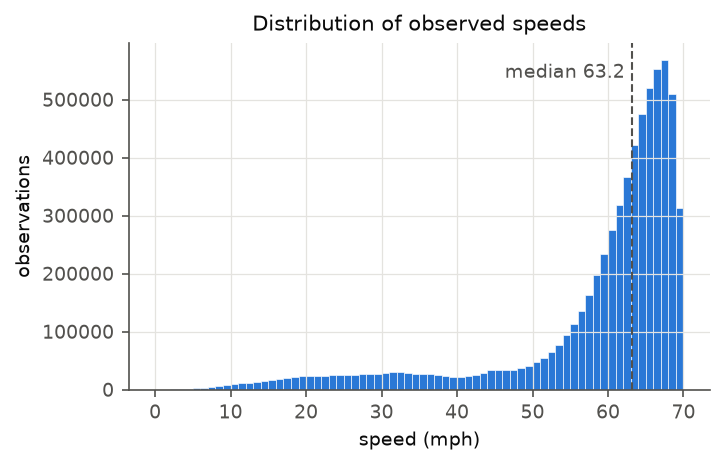

In [4]:
fig, s = eda.distribution(d); s

The distribution is strongly **left-skewed** (skewness ≈ −2). Most of the mass is
free flow at 60–70 mph, with a long congested tail (≈ 11 % of readings below 40 mph).
The errors that matter come from that tail, so we use MAE (robust, median-seeking)
as the training loss and also report RMSE, which weights large congestion errors.

## 2. Temporal structure

{'weekday_min_speed': 45.24900817871094,
 'weekday_min_at_hour': 17.5,
 'weekend_min_speed': 56.79364776611328,
 'weekend_min_at_hour': 13.5,
 'pct_below_40mph': 10.857904323391832}

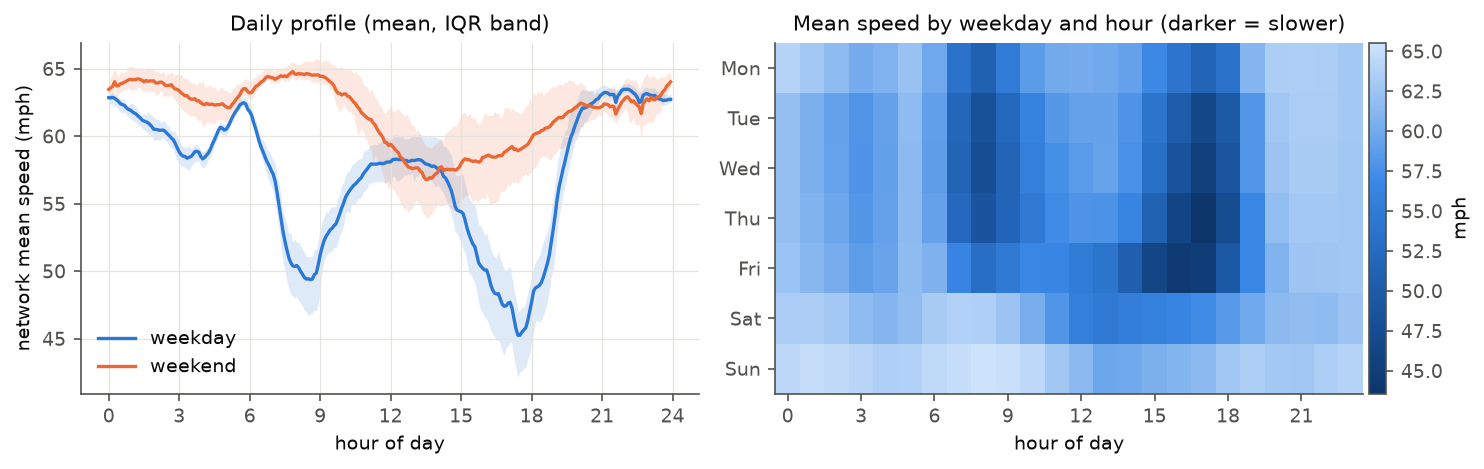

In [5]:
fig, s = eda.daily_profile(d); s

Weekdays show a strong evening rush hour (network mean ≈ 45 mph around 17:30)
and a weaker morning dip. Weekends are much flatter. This motivates the
**calendar** features (time-of-day sin/cos, day-of-week) and the **historical
weekly profile** feature.

{'acf_raw_lag_5min': 0.8598076821252781,
 'acf_raw_lag_1h': 0.5654187720788251,
 'acf_raw_lag_1day': 0.3598100023238646,
 'acf_raw_lag_1week': 0.397925072020966,
 'acf_anomaly_lag_1h': 0.410373686879911,
 'acf_anomaly_lag_1day': 0.07276786058578076}

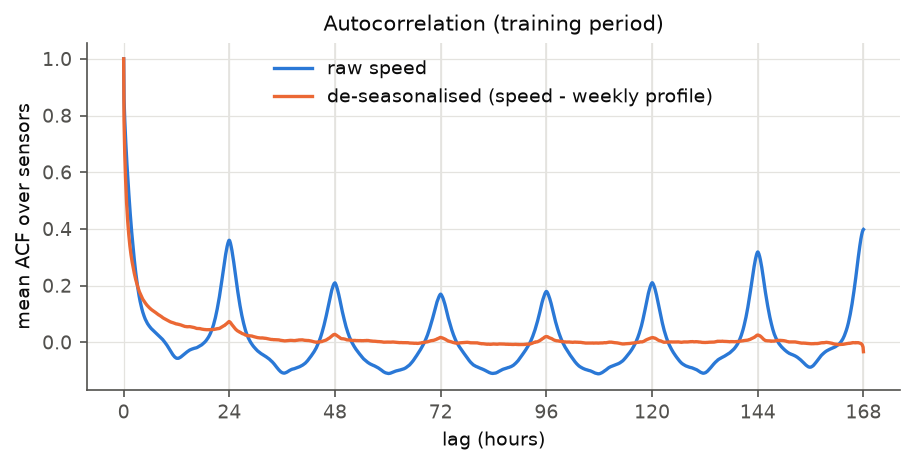

In [6]:
fig, s = eda.autocorrelation(d); s

* The ACF at lag 1 (5 min) is ≈ 0.86, so recent lags are very informative: persistence is a strong 15-min baseline.
* There are clear peaks at every 24 h, and the peak at 168 h (one week) is higher than at 120–144 h, so the seasonality is **weekly**.
* After subtracting the per-sensor weekly profile, the daily peaks almost vanish
  (ACF at 24 h falls from 0.36 to 0.07). The profile therefore captures the
  seasonality, and the remainder is short-memory anomaly. That is exactly the
  decomposition our features use (`profile_target` + `anomaly_now`).

In [7]:
eda.stationarity(d)

{'adf': [{'sensor': '717447',
   'adf_stat': -17.66751600360957,
   'p_value': 3.65777832238924e-30},
  {'sensor': '737529',
   'adf_stat': -16.333022382241985,
   'p_value': 3.0477307309246695e-29},
  {'sensor': '716331',
   'adf_stat': -13.647528013909046,
   'p_value': 1.6089720697502935e-25},
  {'sensor': '760987', 'adf_stat': -21.681259064656388, 'p_value': 0.0},
  {'sensor': '773953', 'adf_stat': -19.616013042512026, 'p_value': 0.0},
  {'sensor': '774067', 'adf_stat': -20.97933077638218, 'p_value': 0.0},
  {'sensor': '717489', 'adf_stat': -18.931542336594056, 'p_value': 0.0},
  {'sensor': '769867',
   'adf_stat': -13.595026016800423,
   'p_value': 2.0027334696717485e-25},
  {'sensor': '717583', 'adf_stat': -20.1639098735474, 'p_value': 0.0},
  {'sensor': '769373',
   'adf_stat': -17.687584314899368,
   'p_value': 3.5844673501927196e-30}],
 'share_rejecting_unit_root_5pct': 1.0}

The Augmented Dickey–Fuller test rejects a unit root for every sampled sensor
(p ≪ 0.01). Speeds are bounded and mean-reverting, so no differencing is needed.
Non-stationarity here is *seasonal* (handled by calendar and profile features),
not stochastic-trend.

## 3. Spatial structure

{'out_degree_mean': 7.318840579710145,
 'out_degree_max': 18,
 'isolated_sensors_no_out_edges': 5,
 'isolated_sensors_no_in_edges': 2,
 'one_way_edge_fraction': 0.7333333333333333}

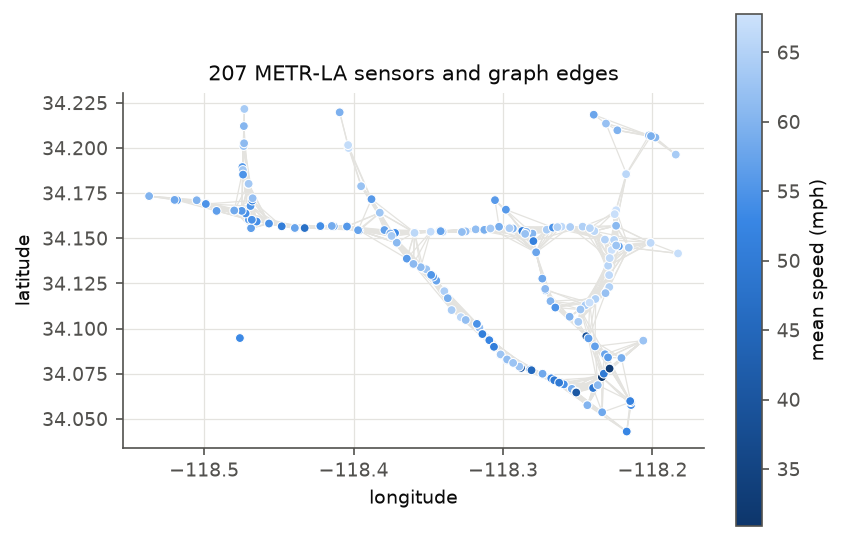

In [8]:
fig, s = eda.sensor_map(d); s

{'corr_anomaly_graph_neighbours': 0.2652717829465686,
 'corr_anomaly_unconnected_pairs': 0.0721116577132372,
 'corr_raw_graph_neighbours': 0.41755685763222566,
 'spearman_distance_vs_anomaly_corr': -0.1962596984339599}

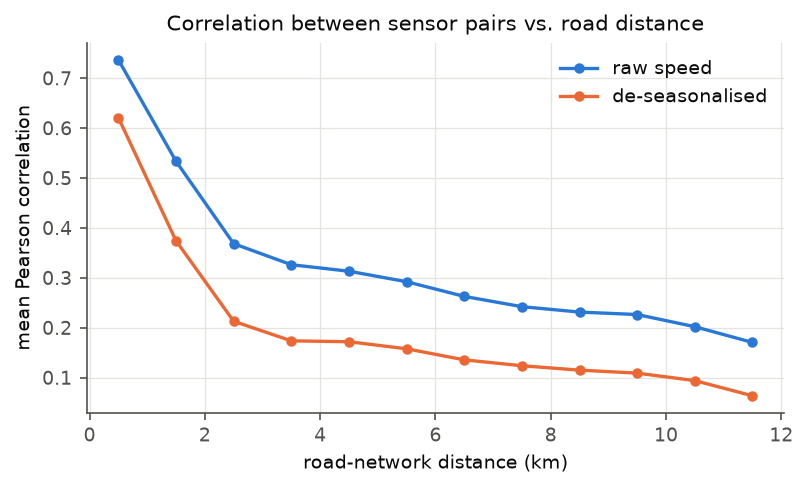

In [9]:
fig, s = eda.spatial_correlation(d, distance_matrix(d.sensor_ids)); s

Correlation decays with road distance, even after removing the shared daily cycle.
Graph neighbours have de-seasonalised correlation ≈ 0.27, against ≈ 0.07 for
unconnected pairs. Congestion therefore **propagates along the network**, which
justifies (i) the spatial up/downstream features and (ii) graph neural networks.
The graph is strongly **directed**: ≈ 73 % of edges have no reverse edge, because
distances are measured along the direction of travel. This is why the diffusion
convolution uses separate forward and backward transition matrices. A few sensors have no out- or in-neighbours, which is one motivation for a *learned* adjacency.

## 4. Split representativeness

{'train': {'mean': 58.58330154418945,
  'std': 12.82396411895752,
  'missing_pct': 7.128092470546796},
 'val': {'mean': 58.89228439331055,
  'std': 13.196234703063965,
  'missing_pct': 6.964843612257132},
 'test': {'mean': 57.75932312011719,
  'std': 13.640379905700684,
  'missing_pct': 12.106703339327902}}

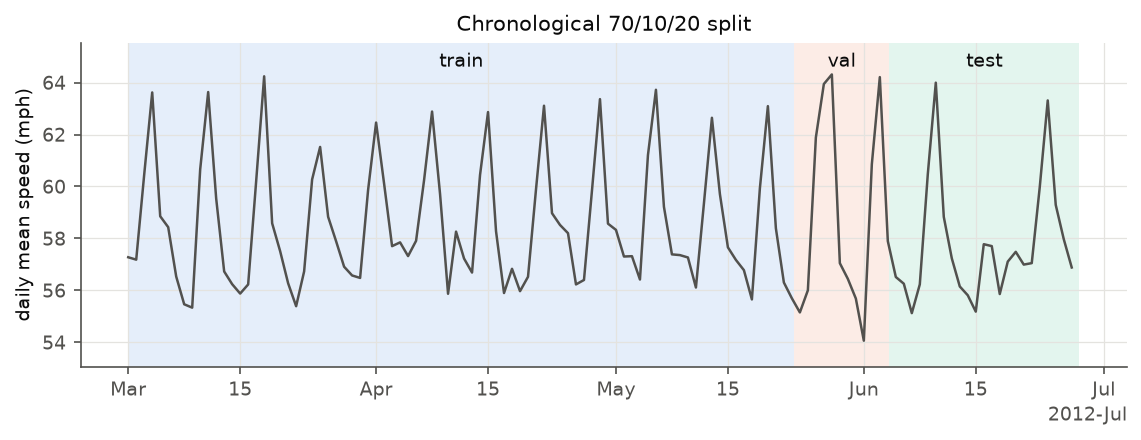

In [10]:
fig, s = eda.split_timeline(d); s

The split is chronological (70/10/20) and windows never cross split boundaries, so
there is no look-ahead leakage. Means are similar across splits, but the **test
period has more missing data (≈ 12 % vs 7 %)** and slightly lower mean speed. This
is a realistic mild distribution shift, and a reason to report confidence intervals.

### Summary of EDA → design decisions
| Finding | Decision |
|---|---|
| zeros = missing | masked loss/metrics; causal forward-fill for features only |
| strong lag-1 ACF | lag features; persistence baseline |
| weekly seasonality | weekly profile & calendar features; HA baseline |
| stationary after seasonality | no differencing; anomaly feature |
| spatial correlation decays with distance | up/downstream features; graph models |
| left-skewed, heavy congestion tail | MAE loss; also report RMSE/MAPE |
| test period has more missing data | robustness analysis; bootstrap CIs |